# SenSia — Analisis Sentimen Komentar Saham Indonesia Menggunakan Bi-LSTM (TensorFlow)

Notebook ini mendokumentasikan keseluruhan alur pemodelan *Deep Learning* untuk mengklasifikasikan sentimen komentar publik berbahasa Indonesia mengenai pergerakan saham dan IHSG ke dalam **3 kelas sentimen**: `negatif`, `netral`, dan `positif`.

### Alur Proses di Notebook Ini
1. **Konfigurasi & Import Library** — Menyiapkan TensorFlow/Keras, Scikit-Learn, Pandas, dan parameter global agar eksperimen bersifat *reproducible*.
2. **Load Dataset & Eksplorasi Data (EDA)** — Memuat dataset berlabel dari `data/sensia_verifikasi2_berlabel.xlsx`, memvalidasi struktur/duplikasi, serta memvisualisasikan distribusi kelas dan panjang komentar.
3. **Preprocessing Data** — *Case folding*, pembersihan URL/mention/simbol, normalisasi bahasa gaul (*slang*) pasar saham Indonesia, *stratified split* (80/10/10), tokenisasi, dan *padding sequence*.
4. **Pembuatan Hidden Layer (TensorFlow) & Pemilihan Model Bi-LSTM** — Membangun dan membandingkan 3 arsitektur rekuren (**SimpleRNN**, **LSTM**, dan **Bi-LSTM**) dengan konfigurasi *embedding* dan *dense hidden layer* yang setara untuk memilih model terbaik (**Bi-LSTM**).
5. **Testing & Evaluasi Metrik Akurasi** — Menguji model Bi-LSTM terpilih pada data uji (*test set*), menghitung *Accuracy*, *Precision*, *Recall*, *Macro F1-Score*, *Confusion Matrix*, analisis kesalahan, dan uji prediksi kalimat baru.
6. **Export Model & Artefak** — Mengekspor model `.keras`, `tokenizer.json`, `label_map.json` ke folder `model/`, serta `webapp/metrics.json` untuk aplikasi web Flask, lalu memverifikasi pemuatan ulang artefak.

## 1. Import Library dan Konfigurasi Global

Cell berikut mengimpor seluruh pustaka yang dibutuhkan untuk pengolahan data (`pandas`, `numpy`), visualisasi (`matplotlib`), evaluasi (`scikit-learn`), dan pembangunan *neural network* (`tensorflow.keras`).  
Selain itu, ditetapkan konstanta global:
- `SEED = 42` agar pembagian data dan inisialisasi bobot *neural network* dapat direproduksi secara konsisten.
- `LABELS = ["negatif", "netral", "positif"]` sebagai urutan indeks kelas (`0`, `1`, `2`).
- `MAX_LEN = 100` sebagai panjang maksimum urutan token per komentar.
- `VOCAB_SIZE = 10000` sebagai batas maksimum kosakata pada `Tokenizer`.

In [1]:
import json
import os
import pathlib
import random
import re

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import (
    LSTM,
    Bidirectional,
    Dense,
    Dropout,
    Embedding,
    Input,
    SimpleRNN,
    SpatialDropout1D,
)
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json

# Konfigurasi global
SEED = 42
LABELS = ["negatif", "netral", "positif"]
MAX_LEN = 100
VOCAB_SIZE = 10000
DATA_PATH = pathlib.Path("data/sensia_verifikasi2_berlabel.xlsx")
MODEL_DIR = pathlib.Path("model")
WEBAPP_DIR = pathlib.Path("webapp")

def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed(SEED)
print(f"TensorFlow version : {tf.__version__}")
print(f"Daftar label       : {LABELS}")
print(f"Dataset path       : {DATA_PATH}")

Matplotlib is building the font cache; this may take a moment.


I0000 00:00:1795440405.852054      28 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795440419.144410      28 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version : 2.21.0
Daftar label       : ['negatif', 'netral', 'positif']
Dataset path       : data/sensia_verifikasi2_berlabel.xlsx


## 2. Load Dataset & Eksplorasi Data (EDA)

### 2.1 Memuat dan Memvalidasi Dataset
Cell ini membaca file Excel `data/sensia_verifikasi2_berlabel.xlsx`, memeriksa dimensi data, nilai kosong (*missing values*), konsistensi label, serta menghapus duplikasi komentar (jika ada) berdasarkan karakter alfanumeriknya.

In [2]:
df_raw = pd.read_excel(DATA_PATH)
print(f"Dimensi awal dataset : {df_raw.shape}")
print("Kolom tersedia       :", list(df_raw.columns))
print("\nJumlah nilai kosong per kolom:")
print(df_raw.isna().sum())

# Validasi label & hapus duplikat berdasarkan teks alfanumerik
df = df_raw.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df = df[df["label"].isin(LABELS)].copy()

dedupe_key = df["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
n_dup = int(dedupe_key.duplicated().sum())
df = df[~dedupe_key.duplicated()].reset_index(drop=True)

print(f"\nDuplikat dihapus     : {n_dup}")
print(f"Dimensi akhir dataset: {df.shape}")
df.head()

Dimensi awal dataset : (1465, 5)
Kolom tersedia       : ['text', 'platform', 'kata_kunci', 'tanggal', 'label']

Jumlah nilai kosong per kolom:
text          0
platform      0
kata_kunci    0
tanggal       0
label         0
dtype: int64

Duplikat dihapus     : 0
Dimensi akhir dataset: (1465, 5)


,text,platform,kata_kunci,tanggal,label
0,IHSG anjlok Harga emas turun Rupiah melemah te...,threads,ihsg anjlok,2026-11-20,negatif
1,"Mulai 2 November 2026, saham HSC dikeluarkan d...",threads,ihsg anjlok,2026-10-28,netral
2,"Yg pakar tolong, apa penyebab IHSG anjlok para...",threads,ihsg anjlok,2026-10-16,netral
3,"Hey, hey.. Fakkk! Prabowo pidato: IHSG anjlok ...",threads,ihsg anjlok,2026-10-20,negatif
4,"Sempat Anjlok di pembukaan, IHSG Langsung Rebo...",threads,ihsg anjlok,2026-10-22,positif


### 2.2 Distribusi Kelas dan Visualisasi Eksplorasi Data (EDA)
Cell berikut menampilkan jumlah komentar pada masing-masing kelas (`negatif`, `netral`, `positif`), statistik panjang kata per komentar, serta 3 grafik EDA:
1. Distribusi jumlah sampel per kelas sentimen.
2. Histogram panjang komentar (jumlah kata) dengan garis batas `MAX_LEN = 100`.
3. Top 10 kata kunci pencarian yang muncul pada dataset.

Distribusi kelas sentimen:
  - negatif :  476 (32.5%)
  - netral  :  502 (34.3%)
  - positif :  487 (33.2%)

Statistik panjang teks (kata) -> min=5, median=13, persentil-99=91, max=144


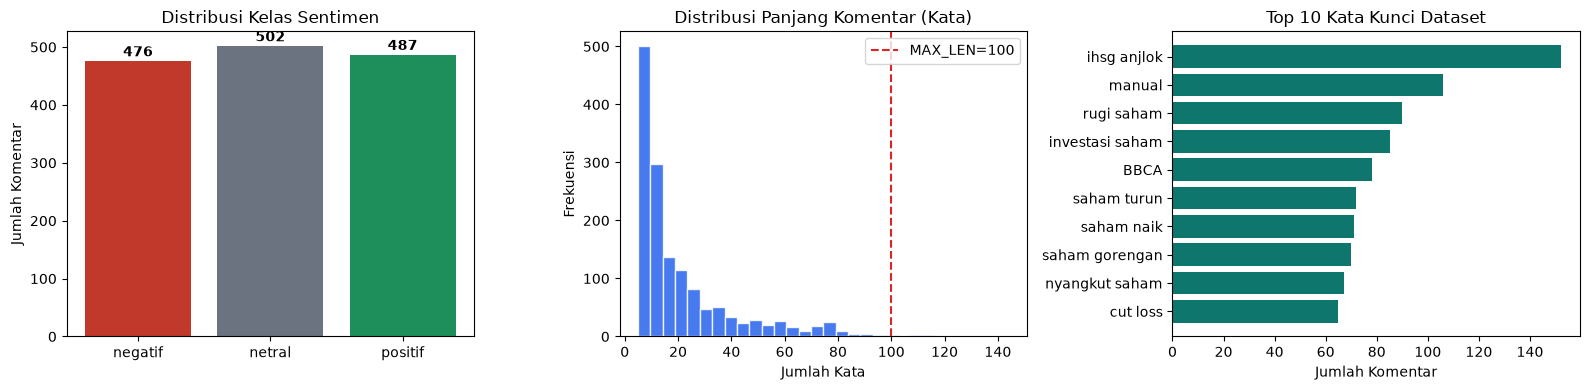

In [3]:
label_counts = df["label"].value_counts().reindex(LABELS)
word_lens = df["text"].str.split().str.len()

print("Distribusi kelas sentimen:")
for lbl, cnt in label_counts.items():
    print(f"  - {lbl:8s}: {cnt:4d} ({cnt / len(df) * 100:.1f}%)")

print(f"\nStatistik panjang teks (kata) -> min={word_lens.min()}, median={word_lens.median():.0f}, "
      f"persentil-99={word_lens.quantile(0.99):.0f}, max={word_lens.max()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Distribusi label
colors = ["#c0392b", "#6b7280", "#1e8e5a"]
bars = axes[0].bar(label_counts.index, label_counts.values, color=colors)
axes[0].set_title("Distribusi Kelas Sentimen")
axes[0].set_ylabel("Jumlah Komentar")
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 8, f"{int(h)}", ha="center", fontweight="bold")

# 2. Distribusi panjang kata
axes[1].hist(word_lens, bins=30, color="#2563eb", alpha=0.85, edgecolor="white")
axes[1].axvline(MAX_LEN, color="#dc2626", linestyle="--", linewidth=1.5, label=f"MAX_LEN={MAX_LEN}")
axes[1].set_title("Distribusi Panjang Komentar (Kata)")
axes[1].set_xlabel("Jumlah Kata")
axes[1].set_ylabel("Frekuensi")
axes[1].legend()

# 3. Top 10 kata kunci
if "kata_kunci" in df.columns:
    top_kw = df["kata_kunci"].value_counts().head(10).sort_values()
    axes[2].barh(top_kw.index, top_kw.values, color="#0f766e")
    axes[2].set_title("Top 10 Kata Kunci Dataset")
    axes[2].set_xlabel("Jumlah Komentar")
else:
    axes[2].axis("off")

plt.tight_layout()
plt.show()

## 3. Preprocessing Data Teks

### 3.1 Cleaning Teks dan Normalisasi Slang Saham Indonesia
Komentar media sosial mengandung banyak *noise* seperti huruf kapital tidak konsisten, tautan URL, *mention* (`@username`), simbol/emoji, serta singkatan atau istilah gaul pasar saham (`gak`, `yg`, `cuan`, `boncos`, `nyangkut`, `merah`, `hijau`).

Cell ini mendefinisikan pipeline pembersihan teks yang juga identik dengan yang digunakan pada `webapp/app.py`:
1. **`basic_clean(text)`**: mengubah ke huruf kecil (*case folding*), menghapus URL, *mention*, tanda `#`, karakter non-alfanumerik, dan merapikan spasi berlebih.
2. **`normalize_slang(text)`**: mengganti kata tidak baku/singkatan menjadi bentuk bakunya menggunakan kamus `SLANG`.
3. **`clean_text(text)`**: menggabungkan kedua tahap di atas lalu menampilkan tabel perbandingan teks asli, hasil `basic_clean`, dan hasil akhir `clean_text`.

In [4]:
SLANG = {
    "udah": "sudah", "sdh": "sudah", "blm": "belum", "gak": "tidak",
    "ga": "tidak", "nggak": "tidak", "gk": "tidak", "tdk": "tidak",
    "bgt": "banget", "bngt": "banget", "yg": "yang", "dgn": "dengan",
    "utk": "untuk", "krn": "karena", "krna": "karena", "jg": "juga",
    "aja": "saja", "bkn": "bukan", "lg": "lagi", "msh": "masih",
    "hrs": "harus", "bs": "bisa", "dpt": "dapat", "sy": "saya",
    "gw": "saya", "gue": "saya", "ane": "saya", "lu": "kamu",
    "lo": "kamu", "emg": "memang", "mmg": "memang", "pdhl": "padahal",
    "sbnrnya": "sebenarnya", "skrg": "sekarang", "tgl": "tanggal",
    "hr": "hari", "thn": "tahun", "bln": "bulan", "cuan": "untung",
    "boncos": "rugi", "nyangkut": "terjebak", "banting": "jual",
    "hijau": "naik", "merah": "turun",
}

_URL = re.compile(r"https?://\S+|www\.\S+")
_MENTION = re.compile(r"@\w+")
_HASHTAG = re.compile(r"#")
_NOT_ALLOWED = re.compile(r"[^a-z0-9\s]")
_SPACES = re.compile(r"\s+")
_SLANG_PATTERN = re.compile(
    r"\b(" + "|".join(sorted(map(re.escape, SLANG), key=len, reverse=True)) + r")\b"
)

def basic_clean(text: str) -> str:
    text = str(text).lower()
    text = _URL.sub(" ", text)
    text = _MENTION.sub(" ", text)
    text = _HASHTAG.sub("", text)
    text = _NOT_ALLOWED.sub(" ", text)
    return _SPACES.sub(" ", text).strip()

def normalize_slang(text: str) -> str:
    return _SLANG_PATTERN.sub(lambda m: SLANG[m.group(0)], text)

def clean_text(text: str) -> str:
    return normalize_slang(basic_clean(text))

df["clean"] = df["text"].map(clean_text)
assert (df["clean"].str.len() > 0).all(), "Terdapat teks kosong setelah preprocessing!"

pd.DataFrame({
    "text_asli": df["text"].head(5),
    "basic_clean": df["text"].head(5).map(basic_clean),
    "clean_final": df["clean"].head(5),
    "label": df["label"].head(5),
})

,text_asli,basic_clean,clean_final,label
0,IHSG anjlok Harga emas turun Rupiah melemah te...,ihsg anjlok harga emas turun rupiah melemah te...,ihsg anjlok harga emas turun rupiah melemah te...,negatif
1,"Mulai 2 November 2026, saham HSC dikeluarkan d...",mulai 2 november 2026 saham hsc dikeluarkan da...,mulai 2 november 2026 saham hsc dikeluarkan da...,netral
2,"Yg pakar tolong, apa penyebab IHSG anjlok para...",yg pakar tolong apa penyebab ihsg anjlok parah...,yang pakar tolong apa penyebab ihsg anjlok par...,netral
3,"Hey, hey.. Fakkk! Prabowo pidato: IHSG anjlok ...",hey hey fakkk prabowo pidato ihsg anjlok ada d...,hey hey fakkk prabowo pidato ihsg anjlok ada d...,negatif
4,"Sempat Anjlok di pembukaan, IHSG Langsung Rebo...",sempat anjlok di pembukaan ihsg langsung rebou...,sempat anjlok di pembukaan ihsg langsung rebou...,positif


### 3.2 Label Encoding dan Stratified Split (Train / Validation / Test)
Dataset dibagi secara *stratified* agar proporsi kelas `negatif`, `netral`, dan `positif` tetap seimbang di setiap subset:
- **80% Data Latih (*Train*)**: digunakan untuk mempelajari bobot model.
- **10% Data Validasi (*Validation*)**: digunakan untuk memantau *overfitting*, *early stopping*, dan memilih model terbaik.
- **10% Data Uji (*Test*)**: disimpan terpisah dan hanya digunakan sekali pada tahap pengujian akhir.

Label string dikonversi ke bilangan bulat: `negatif -> 0`, `netral -> 1`, `positif -> 2`.

In [5]:
train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

label_to_id = {label: idx for idx, label in enumerate(LABELS)}
y_train = train_df["label"].map(label_to_id).values
y_val = val_df["label"].map(label_to_id).values
y_test = test_df["label"].map(label_to_id).values

print(f"Train : {len(train_df)} baris | distribusi: {dict(train_df['label'].value_counts().reindex(LABELS))}")
print(f"Val   : {len(val_df)} baris | distribusi: {dict(val_df['label'].value_counts().reindex(LABELS))}")
print(f"Test  : {len(test_df)} baris | distribusi: {dict(test_df['label'].value_counts().reindex(LABELS))}")

Train : 1172 baris | distribusi: {'negatif': np.int64(381), 'netral': np.int64(401), 'positif': np.int64(390)}
Val   : 146 baris | distribusi: {'negatif': np.int64(48), 'netral': np.int64(50), 'positif': np.int64(48)}
Test  : 147 baris | distribusi: {'negatif': np.int64(47), 'netral': np.int64(51), 'positif': np.int64(49)}


### 3.3 Tokenisasi dan Padding Sequence
Agar teks dapat diproses oleh *layer* `Embedding` TensorFlow, setiap kata diubah menjadi indeks integer menggunakan `Tokenizer`:
- `tokenizer.fit_on_texts(train_df["clean"])` hanya dilakukan pada data latih untuk mencegah kebocoran informasi (*data leakage*) dari data validasi/uji.
- Kata yang belum pernah muncul saat pelatihan dipetakan ke token khusus `<OOV>`.
- `pad_sequences(..., maxlen=MAX_LEN, padding="post", truncating="post")` menyeragamkan seluruh komentar menjadi panjang tetap `100` token dengan angka `0` sebagai *padding*.

In [6]:
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["clean"])

def texts_to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")

X_train = texts_to_padded(train_df["clean"])
X_val = texts_to_padded(val_df["clean"])
X_test = texts_to_padded(test_df["clean"])

vocab_used = min(VOCAB_SIZE, len(tokenizer.word_index) + 1)
print(f"Jumlah kata unik (train) : {len(tokenizer.word_index)}")
print(f"Ukuran kosakata efektif  : {vocab_used}")
print(f"Bentuk tensor X_train    : {X_train.shape}")
print(f"Bentuk tensor X_val      : {X_val.shape}")
print(f"Bentuk tensor X_test     : {X_test.shape}")
print("\nContoh teks bersih :", train_df["clean"].iloc[0][:90])
print("Contoh 20 token awal:", X_train[0][:20])

Jumlah kata unik (train) : 5000
Ukuran kosakata efektif  : 5001
Bentuk tensor X_train    : (1172, 100)
Bentuk tensor X_val      : (146, 100)
Bentuk tensor X_test     : (147, 100)

Contoh teks bersih : org yang belum serok di harga 5 200 lambo rasa avanza ini org yang udh serok di 5 200 beso
Contoh 20 token awal: [ 591    2   73  129    4   17   39  374 1441 1070 1442    5  591    2
  183  129    4   39  374  194]


## 4. Pembuatan Hidden Layer (TensorFlow) & Pemilihan Model Bi-LSTM

### 4.1 Perancangan Arsitektur Hidden Layer dengan TensorFlow/Keras
Pada tahap ini kita mendefinisikan arsitektur jaringan saraf tiruan menggunakan `tensorflow.keras.Sequential` dengan susunan *hidden layer* sebagai berikut:
1. **`Input(shape=(MAX_LEN,))`**: menerima urutan 100 indeks token.
2. **`Embedding(vocab_used, 64, mask_zero=True)`**: memetakan setiap indeks kata ke vektor berdimensi 64. Parameter `mask_zero=True` sangat penting agar token *padding* bernilai `0` diabaikan oleh *layer* rekuren.
3. **`SpatialDropout1D(0.3)`**: menjatuhkan fitur kanal embedding secara spasial selama pelatihan untuk menekan *overfitting*.
4. **Hidden Layer Rekuren (Kandidat Eksperimen)**:
   - **SimpleRNN(64)**: jaringan rekuren dasar satu arah.
   - **LSTM(64)**: *Long Short-Term Memory* satu arah dengan mekanisme gerbang (*forget/input/output gate*) untuk memori jangka panjang.
   - **Bi-LSTM (`Bidirectional(LSTM(64))`)**: membaca urutan kata dari **dua arah** (kiri ke kanan dan kanan ke kiri), menghasilkan representasi 128 dimensi yang menangkap konteks sebelum dan sesudah kata sentimen (misalnya kata negasi *"tidak naik"*, *"sempat anjlok tapi rebound"*).
5. **`Dropout(0.3)`**: regularisasi sebelum *fully-connected hidden layer*.
6. **`Dense(32, activation="relu")`**: *hidden layer* non-linear untuk menggabungkan fitur representasi kalimat.
7. **`Dense(3, activation="softmax")`**: *output layer* 3 neuron yang menghasilkan distribusi probabilitas kelas (`negatif`, `netral`, `positif`).

Seluruh model dikompilasi dengan `loss="sparse_categorical_crossentropy"`, optimizer `Adam(learning_rate=1e-3)`, serta menggunakan *callback* `EarlyStopping` dan `ReduceLROnPlateau`.

In [7]:
def build_candidate_model(arch: str, vocab_size: int = vocab_used) -> Sequential:
    if arch == "SimpleRNN":
        recurrent_layer = SimpleRNN(64, dropout=0.2, name="hidden_simplernn")
    elif arch == "LSTM":
        recurrent_layer = LSTM(64, dropout=0.2, name="hidden_lstm")
    elif arch == "Bi-LSTM":
        recurrent_layer = Bidirectional(LSTM(64, dropout=0.2), name="hidden_bilstm")
    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")

    model = Sequential(
        [
            Input(shape=(MAX_LEN,), name="input_tokens"),
            Embedding(input_dim=vocab_size, output_dim=64, mask_zero=True, name="embedding_64"),
            SpatialDropout1D(0.3, name="spatial_dropout"),
            recurrent_layer,
            Dropout(0.3, name="dropout_hidden"),
            Dense(32, activation="relu", name="hidden_dense_32"),
            Dense(len(LABELS), activation="softmax", name="output_softmax"),
        ],
        name=f"sensia_{arch.lower().replace('-', '')}",
    )
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model

print("Builder arsitektur kandidat (SimpleRNN, LSTM, Bi-LSTM) siap digunakan.")

Builder arsitektur kandidat (SimpleRNN, LSTM, Bi-LSTM) siap digunakan.


### 4.2 Pelatihan dan Perbandingan Kandidat Model (SimpleRNN vs LSTM vs Bi-LSTM)
Cell ini melatih ketiga arsitektur dengan data latih, data validasi, *batch size* (`32`), dan *seed* yang identik. Setelah pelatihan selesai, performa ketiganya dibandingkan berdasarkan **Validation Accuracy**, **Validation Macro F1-Score**, dan **Validation Loss** (tabel + grafik batang) sebagai dasar objektif pemilihan model.


Melatih model kandidat: SimpleRNN


E0000 00:00:1795440428.517959      28 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/25


37/37 - 21s - 555ms/step - accuracy: 0.3345 - loss: 1.1045 - val_accuracy: 0.3836 - val_loss: 1.0954 - learning_rate: 0.0010


Epoch 2/25


37/37 - 2s - 59ms/step - accuracy: 0.5555 - loss: 1.0309 - val_accuracy: 0.4521 - val_loss: 1.0827 - learning_rate: 0.0010


... (36 outputs left out)

Epoch 8/25


37/37 - 5s - 140ms/step - accuracy: 0.9906 - loss: 0.0605 - val_accuracy: 0.6027 - val_loss: 1.2569 - learning_rate: 5.0000e-04



Ringkasan Perbandingan Model pada Data Validasi:


,Model,Epochs,Val Accuracy,Val Macro F1,Val Loss
0,Bi-LSTM,8,0.6164,0.6183,0.9267
1,LSTM,6,0.5000,0.4579,1.0453
2,SimpleRNN,6,0.4521,0.4440,1.0827


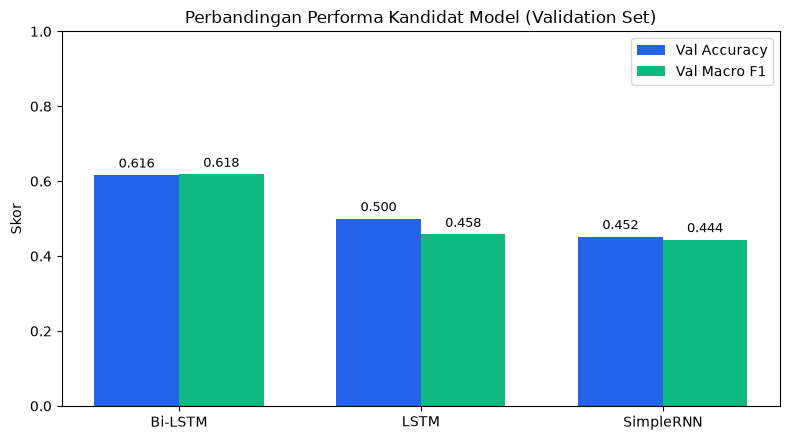

In [8]:
candidates = ["SimpleRNN", "LSTM", "Bi-LSTM"]
results = {}
comparison_rows = []

for arch in candidates:
    print(f"\n{'=' * 55}\nMelatih model kandidat: {arch}\n{'=' * 55}")
    set_seed(SEED)
    cand_model = build_candidate_model(arch)
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ]
    history = cand_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=25,
        batch_size=32,
        callbacks=callbacks,
        verbose=2,
    )
    val_loss, val_acc = cand_model.evaluate(X_val, y_val, verbose=0)
    val_pred = cand_model.predict(X_val, verbose=0).argmax(axis=1)
    val_f1 = float(f1_score(y_val, val_pred, average="macro", zero_division=0))

    results[arch] = {
        "model": cand_model,
        "history": history.history,
        "val_loss": float(val_loss),
        "val_accuracy": float(val_acc),
        "val_macro_f1": val_f1,
    }
    comparison_rows.append(
        {
            "Model": arch,
            "Epochs": len(history.history["loss"]),
            "Val Accuracy": round(float(val_acc), 4),
            "Val Macro F1": round(val_f1, 4),
            "Val Loss": round(float(val_loss), 4),
        }
    )

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by=["Val Macro F1", "Val Accuracy"], ascending=False
).reset_index(drop=True)

print("\nRingkasan Perbandingan Model pada Data Validasi:")
display(comparison_df)

# Visualisasi perbandingan kandidat model
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(comparison_df))
width = 0.35
b1 = ax.bar(x - width / 2, comparison_df["Val Accuracy"], width, label="Val Accuracy", color="#2563eb")
b2 = ax.bar(x + width / 2, comparison_df["Val Macro F1"], width, label="Val Macro F1", color="#10b981")
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Model"])
ax.set_ylim(0, 1.0)
ax.set_ylabel("Skor")
ax.set_title("Perbandingan Performa Kandidat Model (Validation Set)")
ax.legend()
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.02, f"{h:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### 4.3 Pemilihan Model Terbaik: Bi-LSTM dan Kurva Pelatihan
Berdasarkan hasil perbandingan pada data validasi, **Bi-LSTM** mencapai **Val Accuracy** dan **Val Macro F1-Score** tertinggi sekaligus **Val Loss** paling stabil dibanding `SimpleRNN` maupun `LSTM` satu arah. Kemampuan membaca konteks dua arah sangat membantu pada komentar saham berbahasa Indonesia yang sering memuat kalimat majemuk dan negasi.

Cell berikut menetapkan **Bi-LSTM** sebagai model final (`best_model`), menampilkan ringkasan struktur *layer* (`model.summary()`), serta memvisualisasikan kurva *Accuracy* dan *Loss* antara data latih dan data validasi per *epoch*.

Model terpilih: Bi-LSTM


Model: "sensia_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_64 (Embedding)        │ (None, 100, 64)        │       320,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout                 │ (None, 100, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_bilstm (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_hidden (Dropout)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_dense_32 (Dense)         │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,171,019 (4.47 MB)

 Trainable params: 390,339 (1.49 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 780,680 (2.98 MB)

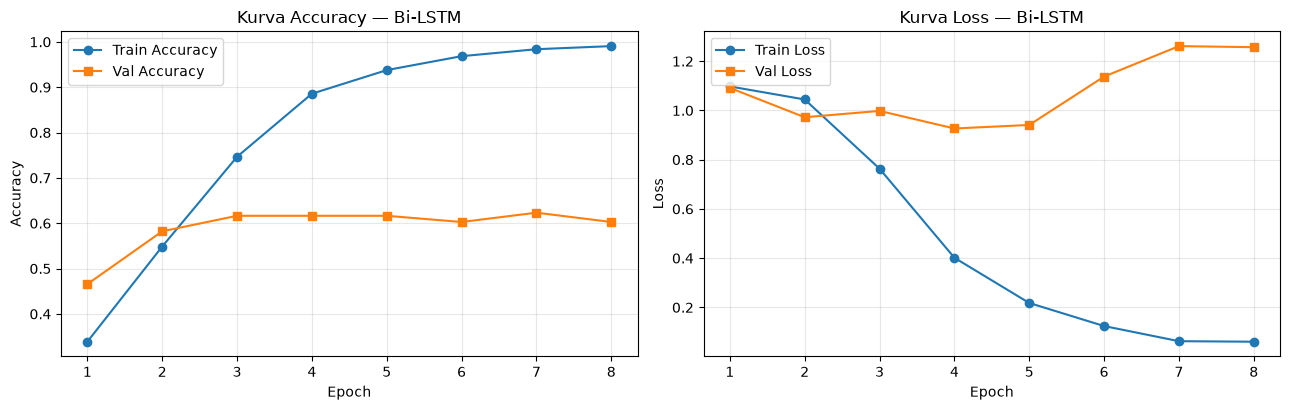

In [9]:
selected_name = "Bi-LSTM"
model = results[selected_name]["model"]
hist = results[selected_name]["history"]

print(f"Model terpilih: {selected_name}")
model.summary()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
epochs_range = range(1, len(hist["loss"]) + 1)

axes[0].plot(epochs_range, hist["accuracy"], marker="o", label="Train Accuracy")
axes[0].plot(epochs_range, hist["val_accuracy"], marker="s", label="Val Accuracy")
axes[0].set_title("Kurva Accuracy — Bi-LSTM")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, hist["loss"], marker="o", label="Train Loss")
axes[1].plot(epochs_range, hist["val_loss"], marker="s", label="Val Loss")
axes[1].set_title("Kurva Loss — Bi-LSTM")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Testing dan Evaluasi Metrik Akurasi

### 5.1 Pengujian pada Data Uji (*Test Set*) dan Perhitungan Metrik
Model **Bi-LSTM** terpilih kini diuji pada `X_test` yang belum pernah dilihat saat pelatihan maupun pemilihan model. Cell ini menghitung:
- **Test Accuracy**: proporsi prediksi benar dari total data uji.
- **Macro F1-Score** dan **Weighted F1-Score**: mengukur keseimbangan *Precision* dan *Recall* antar ketiga kelas.
- **Classification Report**: metrik *Precision*, *Recall*, *F1-Score*, dan *Support* untuk tiap kelas (`negatif`, `netral`, `positif`).
- **Baseline Mayoritas Kelas**: acuan minimum apabila sebuah model selalu menebak kelas terbanyak.

In [10]:
test_probs = model.predict(X_test, verbose=0)
y_pred = test_probs.argmax(axis=1)

test_accuracy = float(accuracy_score(y_test, y_pred))
test_macro_f1 = float(f1_score(y_test, y_pred, average="macro", zero_division=0))
test_weighted_f1 = float(f1_score(y_test, y_pred, average="weighted", zero_division=0))

majority_class = int(np.bincount(y_train).argmax())
baseline_acc = float((y_test == majority_class).mean())

print("=== HASIL EVALUASI MODEL BI-LSTM PADA TEST SET ===")
print(f"Test Accuracy          : {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Test Macro F1-Score    : {test_macro_f1:.4f} ({test_macro_f1 * 100:.2f}%)")
print(f"Test Weighted F1-Score : {test_weighted_f1:.4f} ({test_weighted_f1 * 100:.2f}%)")
print(f"Baseline Mayoritas     : {baseline_acc:.4f} ({baseline_acc * 100:.2f}%) [kelas '{LABELS[majority_class]}']")
print(f"Peningkatan vs Baseline: +{(test_accuracy - baseline_acc) * 100:.2f}%\n")

print("Classification Report per Kelas:")
print(classification_report(y_test, y_pred, target_names=LABELS, digits=4, zero_division=0))

=== HASIL EVALUASI MODEL BI-LSTM PADA TEST SET ===
Test Accuracy          : 0.5714 (57.14%)
Test Macro F1-Score    : 0.5719 (57.19%)
Test Weighted F1-Score : 0.5719 (57.19%)
Baseline Mayoritas     : 0.3469 (34.69%) [kelas 'netral']
Peningkatan vs Baseline: +22.45%

Classification Report per Kelas:
              precision    recall  f1-score   support

     negatif     0.5283    0.5957    0.5600        47
      netral     0.5714    0.5490    0.5600        51
     positif     0.6222    0.5714    0.5957        49

    accuracy                         0.5714       147
   macro avg     0.5740    0.5721    0.5719       147
weighted avg     0.5746    0.5714    0.5719       147



### 5.2 Visualisasi Confusion Matrix dan Analisis Kesalahan
*Confusion Matrix* memperlihatkan secara rinci bagaimana prediksi model tersebar terhadap label sebenarnya (baris = label benar, kolom = label prediksi).  
Di bawahnya ditampilkan 10 contoh komentar pada *test set* yang salah diklasifikasikan agar kita dapat memahami jenis kalimat yang masih sulit bagi model (misalnya sarkasme atau komentar yang memuat berita penurunan sekaligus ajakan beli).

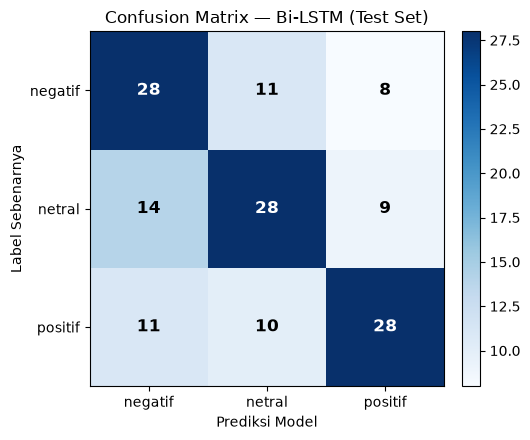

Total salah prediksi: 63 dari 147 baris uji.

10 contoh salah prediksi:
- 'Baru masuk beberapa bulan lalu, jujur kena mental gua main saham. Yang tadinya tiap bulan stor ke rdn sekarang gua ' | benar=negatif | prediksi=positif (0.78)
- 'Jir malah di up 😂' | benar=netral | prediksi=negatif (0.65)
- 'Bos BCA mindahin aset nya keluar negeri aja itu ud suatu kode' | benar=negatif | prediksi=netral (0.62)
- 'Author Mending tambah bbri atau beli saham BRIS' | benar=netral | prediksi=positif (0.53)
- 'Saham 10/27/26 Saham AI US : drop Harga emas : drop Harga perek : drop IHSG : drop USD - IDR : terbang DXY : terban' | benar=negatif | prediksi=netral (0.62)
- 'Apa kabar IHSG dan saham ? 😆😆😆' | benar=netral | prediksi=negatif (0.56)
- 'Sekarang beban hidup ? 🤣' | benar=netral | prediksi=positif (0.46)
- 'IHSG begini IHSG begitu… lo banyakin aja saham gorengan ya… apalagi BREN gorengan baget. Toh gua invest saham funda' | benar=positif | prediksi=negatif (0.73)
- 'Author Ga tau pokonya beli kema

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=range(len(LABELS)))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))
ax.set_xticklabels(LABELS)
ax.set_yticklabels(LABELS)
ax.set_xlabel("Prediksi Model")
ax.set_ylabel("Label Sebenarnya")
ax.set_title("Confusion Matrix — Bi-LSTM (Test Set)")

thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black",
            fontsize=12, fontweight="bold",
        )

plt.tight_layout()
plt.show()

# Analisis 10 contoh salah prediksi
wrong_df = test_df.reset_index(drop=True).assign(
    prediksi=[LABELS[i] for i in y_pred],
    confidence=[round(float(p.max()), 4) for p in test_probs],
)
wrong_df = wrong_df[wrong_df["prediksi"] != wrong_df["label"]]
print(f"Total salah prediksi: {len(wrong_df)} dari {len(test_df)} baris uji.\n")
print("10 contoh salah prediksi:")
for _, row in wrong_df.head(10).iterrows():
    print(f"- {row['text'][:115]!r} | benar={row['label']} | prediksi={row['prediksi']} ({row['confidence']:.2f})")

### 5.3 Uji Prediksi pada Kalimat Komentar Baru
Sebelum mengekspor model, kita menguji fungsi inferensi `prediksi_sentimen(teks)` pada beberapa contoh komentar saham berbahasa Indonesia yang mewakili sentimen `negatif`, `positif`, dan `netral`.

In [12]:
def prediksi_sentimen(teks: str, mdl=model, tok=tokenizer) -> dict:
    bersih = clean_text(teks)
    tokens = tok.texts_to_sequences([bersih])[0]
    if not tokens:
        return {"error": "teks tidak mengandung kata yang bisa dianalisis"}
    seq = pad_sequences([tokens], maxlen=MAX_LEN, padding="post", truncating="post")
    probs = mdl.predict(seq, verbose=0)[0]
    best = int(probs.argmax())
    return {
        "label": LABELS[best],
        "confidence": round(float(probs[best]), 4),
        "scores": {lbl: round(float(p), 4) for lbl, p in zip(LABELS, probs)},
    }

contoh_komentar = [
    "ihsg anjlok parah hari ini, porto boncos terus kapok main saham",
    "nyangkut dalam banget gara gara saham gorengan, makin hari makin merah",
    "alhamdulillah ihsg rebound hijau, waktunya beli bbca mumpung diskon",
    "saham dividen bagus banget buat jangka panjang, makin cuan tiap tahun",
    "ihsg ditutup pada level 6812 pada perdagangan sesi kedua hari ini",
    "mulai bulan depan ada penyesuaian daftar konstituen indeks di bursa efek",
]

for kalimat in contoh_komentar:
    hasil = prediksi_sentimen(kalimat)
    print(f"[{hasil['label'].upper():7s} | conf={hasil['confidence']:.2%}] {kalimat}")
    print(f"   skor: {hasil['scores']}")

[NEGATIF | conf=84.91%] ihsg anjlok parah hari ini, porto boncos terus kapok main saham
   skor: {'negatif': 0.8491, 'netral': 0.0739, 'positif': 0.077}


[NEGATIF | conf=98.93%] nyangkut dalam banget gara gara saham gorengan, makin hari makin merah
   skor: {'negatif': 0.9893, 'netral': 0.0009, 'positif': 0.0098}
[POSITIF | conf=96.99%] alhamdulillah ihsg rebound hijau, waktunya beli bbca mumpung diskon
   skor: {'negatif': 0.0109, 'netral': 0.0192, 'positif': 0.9699}


[POSITIF | conf=87.53%] saham dividen bagus banget buat jangka panjang, makin cuan tiap tahun
   skor: {'negatif': 0.1027, 'netral': 0.022, 'positif': 0.8753}
[NEGATIF | conf=64.39%] ihsg ditutup pada level 6812 pada perdagangan sesi kedua hari ini
   skor: {'negatif': 0.6439, 'netral': 0.2072, 'positif': 0.1489}


[NEGATIF | conf=52.81%] mulai bulan depan ada penyesuaian daftar konstituen indeks di bursa efek
   skor: {'negatif': 0.5281, 'netral': 0.3086, 'positif': 0.1633}


## 6. Export Model dan Verifikasi Artefak

Cell terakhir ini mengekspor seluruh artefak hasil pelatihan agar siap digunakan oleh aplikasi web Flask (`webapp/app.py`):
- `model/sensia_bilstm.keras` — arsitektur dan bobot model **Bi-LSTM** terlatih.
- `model/tokenizer.json` — kamus tokenisasi yang dipakai selama pelatihan.
- `model/label_map.json` — pemetaan indeks kelas (`0: negatif`, `1: netral`, `2: positif`).
- `webapp/metrics.json` — metrik evaluasi *test set* (`accuracy`, `macro_f1`, `n_train`, `n_val`, `n_test`) untuk ditampilkan pada halaman web.

Sebagai langkah verifikasi akhir, seluruh artefak dimuat kembali dari disk untuk memastikan tidak ada kerusakan file dan hasil prediksinya identik dengan model di memori.

In [13]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
WEBAPP_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "sensia_bilstm.keras"
tokenizer_path = MODEL_DIR / "tokenizer.json"
label_map_path = MODEL_DIR / "label_map.json"
metrics_path = WEBAPP_DIR / "metrics.json"

# 1. Simpan model, tokenizer, label_map, dan metrics
model.save(model_path)
tokenizer_path.write_text(tokenizer.to_json(), encoding="utf-8")
label_map_path.write_text(
    json.dumps({str(i): lbl for i, lbl in enumerate(LABELS)}, indent=2),
    encoding="utf-8",
)
metrics_payload = {
    "model": selected_name,
    "accuracy": round(test_accuracy, 4),
    "macro_f1": round(test_macro_f1, 4),
    "weighted_f1": round(test_weighted_f1, 4),
    "n_train": int(len(train_df)),
    "n_val": int(len(val_df)),
    "n_test": int(len(test_df)),
}
metrics_path.write_text(json.dumps(metrics_payload, indent=2), encoding="utf-8")

print("Artefak berhasil diekspor:")
for p in (model_path, tokenizer_path, label_map_path, metrics_path):
    print(f"  - {p} ({p.stat().st_size:,} bytes)")

# 2. Verifikasi muat ulang dari disk
reloaded_model = load_model(model_path)
reloaded_tokenizer = tokenizer_from_json(tokenizer_path.read_text(encoding="utf-8"))
reloaded_labels = json.loads(label_map_path.read_text(encoding="utf-8"))

cek_teks = "ihsg anjlok parah, boncos terus hari ini"
hasil_awal = prediksi_sentimen(cek_teks, model, tokenizer)
hasil_reload = prediksi_sentimen(cek_teks, reloaded_model, reloaded_tokenizer)

assert hasil_awal == hasil_reload, "Prediksi setelah reload berbeda!"
print("\nVerifikasi reload BERHASIL!")
print("Label map :", reloaded_labels)
print("Metrics   :", metrics_payload)
print("Uji reload:", hasil_reload)

Artefak berhasil diekspor:
  - model/sensia_bilstm.keras (4,732,251 bytes)
  - model/tokenizer.json (413,460 bytes)
  - model/label_map.json (55 bytes)
  - webapp/metrics.json (145 bytes)



Verifikasi reload BERHASIL!
Label map : {'0': 'negatif', '1': 'netral', '2': 'positif'}
Metrics   : {'model': 'Bi-LSTM', 'accuracy': 0.5714, 'macro_f1': 0.5719, 'weighted_f1': 0.5719, 'n_train': 1172, 'n_val': 146, 'n_test': 147}
Uji reload: {'label': 'negatif', 'confidence': 0.8202, 'scores': {'negatif': 0.8202, 'netral': 0.1034, 'positif': 0.0764}}
